In [130]:
import pandas as pd
import seaborn as sns
from numpy import unique
import matplotlib.pyplot as plt

##  **Data importation**

Data Description

- **Date** – date we collected data.
- **Location** – Name of the city from Australia.
- **MinTemp** – The minimum temperature during a particular day (°C).
- **MaxTemp** – The maximum temperature during a particular day (°C).
- **Rainfall** – Rainfall during a particular day (mm).
- **Evaporation** – Evaporation during a particular day (mm).
- **Sunshine** – Bright sunshine during a particular day (hours).
- **WindGusDir** – The direction of the strongest gust during a particular day (16 compass points).
- **WindGustSpeed** – Speed of strongest gust during a particular day (km/h).
- **WindDir9am** – The direction of the wind for 10 min prior to 9 am (compass points).
- **WindDir3pm** – The direction of the wind for 10 min prior to 3 pm (compass points).
- **WindSpeed9am** – Speed of the wind for 10 min prior to 9 am (km/h).
- **WindSpeed3pm** – Speed of the wind for 10 min prior to 3 pm (km/h).
- **Humidity9am** – The humidity of the wind at 9 am (percent).
- **Humidity3pm** – The humidity of the wind at 3 pm (percent).
- **Pressure9am** – Atmospheric pressure at 9 am (hectopascals).
- **Pressure3pm** – Atmospheric pressure at 3 pm (hectopascals).
- **Cloud9am** – Cloud-obscured portions of the sky at 9 am (eighths).
- **Cloud3pm** – Cloud-obscured portions of the sky at 3 pm (eighths).
- **Temp9am** – The temperature at 9 am (°C).
- **Temp3pm** – The temperature at 3 pm (°C).
- **RainToday** – If today is rainy then 'Yes', otherwise 'No'.
- **RainTomorrow** – If tomorrow is rainy then 1 (Yes), otherwise 0 (No).

In [172]:
target_dir = '../data/raw'
data = pd.read_csv(target_dir+'/weatherAUS.csv')
data_copy = data.copy()

In [173]:
data.head(5)

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [174]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null

In [175]:
data.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,143975.000000,144199.000000,142199.000000,82670.000000,75625.000000,135197.000000,143693.000000,142398.000000,142806.000000,140953.000000,130395.00000,130432.000000,89572.000000,86102.000000,143693.000000,141851.00000
mean,12.194034,23.221348,2.360918,5.468232,7.611178,40.035230,14.043426,18.662657,68.880831,51.539116,1017.64994,1015.255889,4.447461,4.509930,16.990631,21.68339
std,6.398495,7.119049,8.478060,4.193704,3.785483,13.607062,8.915375,8.809800,19.029164,20.795902,7.10653,7.037414,2.887159,2.720357,6.488753,6.93665
min,-8.500000,-4.800000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.50000,977.100000,0.000000,0.000000,-7.200000,-5.40000
25%,7.600000,17.900000,0.000000,2.600000,4.800000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.90000,1010.400000,1.000000,2.000000,12.300000,16.60000
50%,12.000000,22.600000,0.000000,4.800000,8.400000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.60000,1015.200000,5.000000,5.000000,16.700000,21.10000
75%,16.900000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.40000,1020.000000,7.000000,7.000000,21.600000,26.40000
max,33.900000,48.100000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.00000,1039.600000,9.000000,9.000000,40.200000,46.70000


In [243]:
categorical_variables=data.select_dtypes(include=['object']).columns.to_list()
numerical_variables=data.select_dtypes(exclude=['object']).columns.to_list()

print(f"Number of Categorical variables ({len(categorical_variables)}) {categorical_variables}\n")
print(f"Number of Numerical variables ({len(numerical_variables)}) {numerical_variables}")

Number of Categorical variables (6) ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']

Number of Numerical variables (17) ['Date', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']


In [177]:
for col in categorical_variables:
    print(f"\n {data.loc[:, col].value_counts(dropna=False)}")


 Date
2013-11-12    49
2014-09-01    49
2014-08-23    49
2014-08-24    49
2014-08-25    49
              ..
2007-11-29     1
2007-11-28     1
2007-11-27     1
2007-11-26     1
2008-01-31     1
Name: count, Length: 3436, dtype: int64

 Location
Canberra            3436
Sydney              3344
Darwin              3193
Melbourne           3193
Brisbane            3193
Adelaide            3193
Perth               3193
Hobart              3193
Albany              3040
MountGambier        3040
Ballarat            3040
Townsville          3040
GoldCoast           3040
Cairns              3040
Launceston          3040
AliceSprings        3040
Bendigo             3040
Albury              3040
MountGinini         3040
Wollongong          3040
Newcastle           3039
Tuggeranong         3039
Penrith             3039
Woomera             3009
Nuriootpa           3009
Cobar               3009
CoffsHarbour        3009
Moree               3009
Sale                3009
PerthAirport        3009
Pearc

In [178]:
data.shape

(145460, 23)

**Summary of overview of data**

- *Categorical variables*

1. There are 6 (7) categorical variables. 
2. These are given by Location, WindGustDir, WindDir9am, WindDir3pm, RainToday and RainTomorrow (Date).
3. There are two binary categorical variables - RainToday and RainTomorrow.
4. *Date* appears as categorical variable but it should be a date variable.
5. The four others are nominal variables.
6. RainTomorrow is the target variable.

- *Numerical variables*
-- There are 16 numeric variables.

## Basic Data Cleaning

0. **Set Date in the good format**

In [179]:
data['Date'] = pd.to_datetime(data['Date'], format ='%Y-%m-%d')

In [180]:
data[['Date']].head()

,Date
0,2008-12-01
1,2008-12-02
2,2008-12-03
3,2008-12-04
4,2008-12-05


In [181]:
print(data['Date'].min(), '→', data['Date'].max())
print(f"Span: {(data['Date'].max() - data['Date'].min()).days} days")   

2007-11-01 00:00:00 → 2017-06-25 00:00:00
Span: 3524 days


1. **Zero variance - column with a single value**

In [182]:
for i in range(data.shape[1]):
    #print(data.columns[i]}, data.iloc[:, i].nunique())
    print('%-15s %5d' % (data.columns[i], data.iloc[:, i].nunique()))

Date             3436
Location           49
MinTemp           389
MaxTemp           505
Rainfall          681
Evaporation       358
Sunshine          145
WindGustDir        16
WindGustSpeed      67
WindDir9am         16
WindDir3pm         16
WindSpeed9am       43
WindSpeed3pm       44
Humidity9am       101
Humidity3pm       101
Pressure9am       546
Pressure3pm       549
Cloud9am           10
Cloud3pm           10
Temp9am           441
Temp3pm           502
RainToday           2
RainTomorrow        2


2.  **Numerical columns with very few value**

In [183]:
# get number of unique values for each column
counts = data.nunique()

# record columns to potentialy delete
for i, v in enumerate(counts):
    perc = (float(v)/data.shape[0]*100)
    if data.columns[i] in numerical_variables and perc < 1:
        print('%-15s %3d| %.2f%%' % (data.columns[i], v, perc))

MinTemp         389| 0.27%
MaxTemp         505| 0.35%
Rainfall        681| 0.47%
Evaporation     358| 0.25%
Sunshine        145| 0.10%
WindGustSpeed    67| 0.05%
WindSpeed9am     43| 0.03%
WindSpeed3pm     44| 0.03%
Humidity9am     101| 0.07%
Humidity3pm     101| 0.07%
Pressure9am     546| 0.38%
Pressure3pm     549| 0.38%
Cloud9am         10| 0.01%
Cloud3pm         10| 0.01%
Temp9am         441| 0.30%
Temp3pm         502| 0.35%


3. **Rows that contains duplicated data**

In [184]:
# calculate duplicate
dups = data.duplicated()
# report if there are any duplicates
print(dups.any())
# list all duplicate rows
print(data[dups])

False
Empty DataFrame
Columns: [Date, Location, MinTemp, MaxTemp, Rainfall, Evaporation, Sunshine, WindGustDir, WindGustSpeed, WindDir9am, WindDir3pm, WindSpeed9am, WindSpeed3pm, Humidity9am, Humidity3pm, Pressure9am, Pressure3pm, Cloud9am, Cloud3pm, Temp9am, Temp3pm, RainToday, RainTomorrow]
Index: []

[0 rows x 23 columns]


4. **Likelihood Numerical data**

In [185]:
# 
print('MinTemp above MaxTemp                 :', int((data.MinTemp > data.MaxTemp).sum()))
print('negative Rainfall                     :', int((data.Rainfall < 0).sum()))
print('humidity outside 0-100                :', int(((data[['Humidity9am', 'Humidity3pm']] < 0) | (data[['Humidity9am', 'Humidity3pm']] > 100)).sum().sum()))
print('humidity exactly 0                    :', int((data[['Humidity9am', 'Humidity3pm']] == 0).sum().sum()))
print('cloud above 8 [Cloud9am, Cloud3pm]    :', int((data[['Cloud9am', 'Cloud3pm']] > 8).sum().sum()))
print('wind speed above gust speed           :', int(((data.WindSpeed9am > data.WindGustSpeed) | (data.WindSpeed3pm > data.WindGustSpeed)).sum()))
print('RainToday disagrees with Rainfall > 1mm:', int((((data.Rainfall > 1) & (data.RainToday == 'No')) | ((data.Rainfall <= 1) & (data.RainToday == 'Yes'))).sum()))

MinTemp above MaxTemp                 : 0
negative Rainfall                     : 0
humidity outside 0-100                : 0
humidity exactly 0                    : 5
cloud above 8 [Cloud9am, Cloud3pm]    : 3
wind speed above gust speed           : 5
RainToday disagrees with Rainfall > 1mm: 0


5.  **Sanity Checks**

In [186]:
# Is Date monotonically increasing per station?
sorted_check = data.groupby('Location')['Date'].apply(lambda s: s.is_monotonic_increasing)
print(f"Stations not sorted: {(~sorted_check).sum()}")

Stations not sorted: 0


In [283]:
# Are there gaps > 7 days between consecutive observations per station?
data_sorted = data.sort_values(['Location', 'Date'])
gaps = data_sorted.groupby('Location')['Date'].diff().dt.days
print(f"Locations with gaps > 7 days: {(gaps > 7).groupby(data_sorted['Location']).any().sum()}")

Locations with gaps > 7 days: 46


**Conclusion**:

-  There are no variables with zero variance.
-  The variable that have few value *0.01%* could be consider as ordinal variables, they are still valid.
-  There is no duplicated rows.
-  There are 5 rows with humidity value equal to 0 (to be delete)
-  There are 3 rows with cloud obscured portion of the sky greater than 8 (to be deleted)
-  There are 5 rows with the gust speed is below the wind speed.
-  There are 46 location with gaps in data collection greater than 7 days

## Mark and remove Missing Data

1.  **per-column counts + heatmap**

In [188]:
for i in range(data.shape[1]):
    # count number of rows with missing values
    n_miss = data.iloc[:, i].isnull().sum()  # df[[i]] index the columns i as dataframe, df[i] index the column i but as series
    perc = n_miss / data.shape[0] * 100  # if you want to index row you should use loc (location) or iloc (integer location)
    print('> %-15s-> Missing: %6d (%5.1f%%)' % (data.columns[i], n_miss, perc))

> Date           -> Missing:      0 (  0.0%)
> Location       -> Missing:      0 (  0.0%)
> MinTemp        -> Missing:   1485 (  1.0%)
> MaxTemp        -> Missing:   1261 (  0.9%)
> Rainfall       -> Missing:   3261 (  2.2%)
> Evaporation    -> Missing:  62790 ( 43.2%)
> Sunshine       -> Missing:  69835 ( 48.0%)
> WindGustDir    -> Missing:  10326 (  7.1%)
> WindGustSpeed  -> Missing:  10263 (  7.1%)
> WindDir9am     -> Missing:  10566 (  7.3%)
> WindDir3pm     -> Missing:   4228 (  2.9%)
> WindSpeed9am   -> Missing:   1767 (  1.2%)
> WindSpeed3pm   -> Missing:   3062 (  2.1%)
> Humidity9am    -> Missing:   2654 (  1.8%)
> Humidity3pm    -> Missing:   4507 (  3.1%)
> Pressure9am    -> Missing:  15065 ( 10.4%)
> Pressure3pm    -> Missing:  15028 ( 10.3%)
> Cloud9am       -> Missing:  55888 ( 38.4%)
> Cloud3pm       -> Missing:  59358 ( 40.8%)
> Temp9am        -> Missing:   1767 (  1.2%)
> Temp3pm        -> Missing:   3609 (  2.5%)
> RainToday      -> Missing:   3261 (  2.2%)
> RainTomo

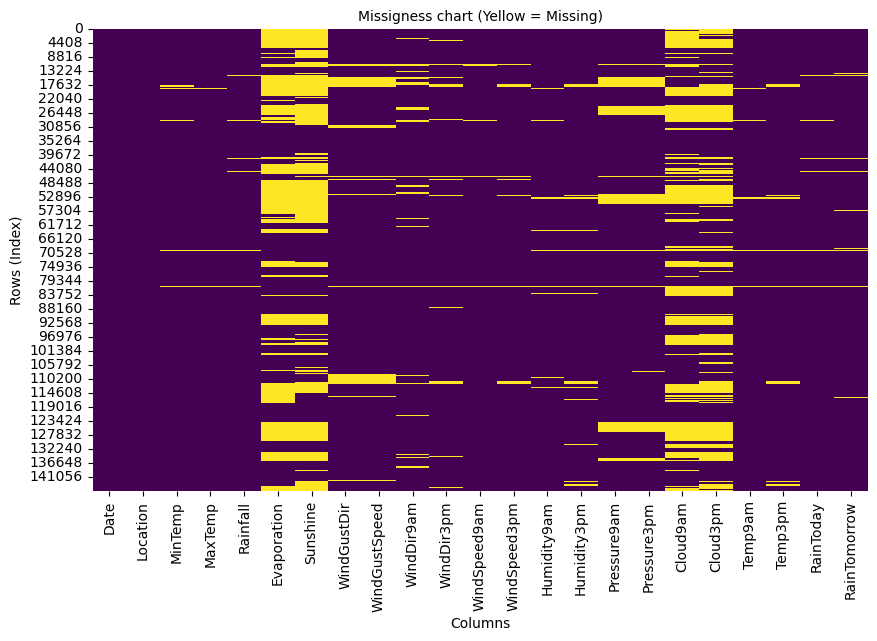

In [189]:
plt.figure(figsize=(10, 6))
# cbar=False remove the legend (0 = present, 1 = missing)
# yticklabels=False masque les index de lignes trop denses
sns.heatmap(data.isnull(), cbar=False, cmap='viridis')

plt.title("Missigness chart (Yellow = Missing)", fontsize=10)
plt.xlabel("Columns")
plt.ylabel("Rows (Index)")
plt.show()

2. **Missingness by Location**

In [190]:
pd.DataFrame({
    'missing_pct': (data.drop(columns=['Location']).isna().mean() * 100).round(1),
    'locations_with_no_data': data.groupby('Location').apply(lambda g: g.isna().all(), include_groups=False).sum(),
}).sort_values('missing_pct', ascending=False)

,missing_pct,locations_with_no_data
Sunshine,48.0,19
Evaporation,43.2,16
Cloud3pm,40.8,12
Cloud9am,38.4,12
Pressure9am,10.4,4
Pressure3pm,10.3,4
WindDir9am,7.3,0
WindGustDir,7.1,2
WindGustSpeed,7.1,2
Humidity3pm,3.1,0


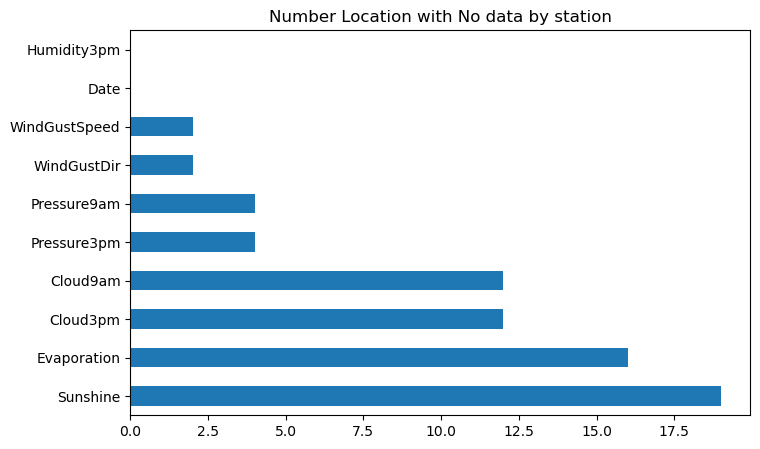

In [191]:
miss_by_loc = data.groupby('Location').apply(lambda g: g.isna().all(), include_groups=False).sum().sort_values(ascending=False)
miss_by_loc.head(10).plot.barh(figsize=(8, 5))
plt.title('Number Location with No data by station')
plt.show()   

3.  **block vs random gaps (one example)**

In [ ]:
import numpy as np

# Pick one station with notable missingness (e.g. the top one from your earlier plot)
station = 'Albury'  # or whatever had the most missing
sub = df[df['Location'] == station].sort_values('Date').reset_index(drop=True)

# Flag missing
is_na = sub['Rainfall'].isna()

# Group consecutive runs of True/False
run_id = (is_na != is_na.shift()).cumsum()
run_len = is_na.groupby(run_id).transform('sum')

# Only look at runs that ARE missing
missing_runs = run_len[is_na]
print(f"Station: {station}")
print(f"Total missing days: {is_na.sum()}")
print(f"Number of separate gaps: {missing_runs.groupby(run_id[is_na]).ngroups}")
print(f"Max consecutive missing days: {missing_runs.max()}")
print(f"Median gap length: {missing_runs.median()}")

# Interpretation:
# - If max gap >> median → block missingness (station went offline for a period)
# - If most gaps are 1 day → random sensor dropouts   

4.  **RainTomorrow vs RainToday  Missigness**

In [208]:
# Indices where RainTomorrow is NaN
idx_tomorrow = data['RainTomorrow'].isna()
# Indices where RainToday is NaN
idx_today = data['RainToday'].isna()

# 1. Common to both
both = data[idx_tomorrow & idx_today].index

# 2. Only in RainTomorrow
only_tomorrow = data[idx_tomorrow & ~idx_today].index

# 3. Only in RainToday
only_today = data[~idx_tomorrow & idx_today].index

# 4. different
xor = data[idx_tomorrow ^ idx_today].index

# 5. Resume
print(f"NaN RainTomorrow: {idx_tomorrow.sum()}")
print(f"NaN RainToday:    {idx_today.sum()}")
print(f"Commun:          {len(both)}")
print(f"Uniques RainTomorrow: {len(only_tomorrow)}")
print(f"Uniques RainToday:    {len(only_today)}")   

NaN RainTomorrow: 3267
NaN RainToday:    3261
Commun:          1855
Uniques RainTomorrow: 1412
Uniques RainToday:    1406


4.  **Mark impossible values → NaN (cloud>8, humidity==0)**

In [209]:
df = data.copy()

In [210]:
oktas = ['Cloud9am', 'Cloud3pm']
humidity = ['Humidity9am', 'Humidity3pm']
df[oktas] = df[oktas].where(df[oktas] <= 8)
df[humidity] = df[humidity].where(df[humidity] > 0)

In [211]:
df = df.dropna(subset=['RainTomorrow'], ignore_index=True)

In [212]:
df.shape

(142193, 23)

**Missingness** : Our data is partially missing not at random.

*  Rows without RainTomorrow are dropped, because the target cannot be filled in without inventing labels.
*  Cloud above 8 oktas and humidity of exactly 0 are impossible or sensor errors, so they become missing.
*  There are some locations which registered no data; this is certainly due to the degrading of sensor 

## Outlier Identification and Removal

1. **Barplot of numerical variable**

In [226]:
import seaborn as sns

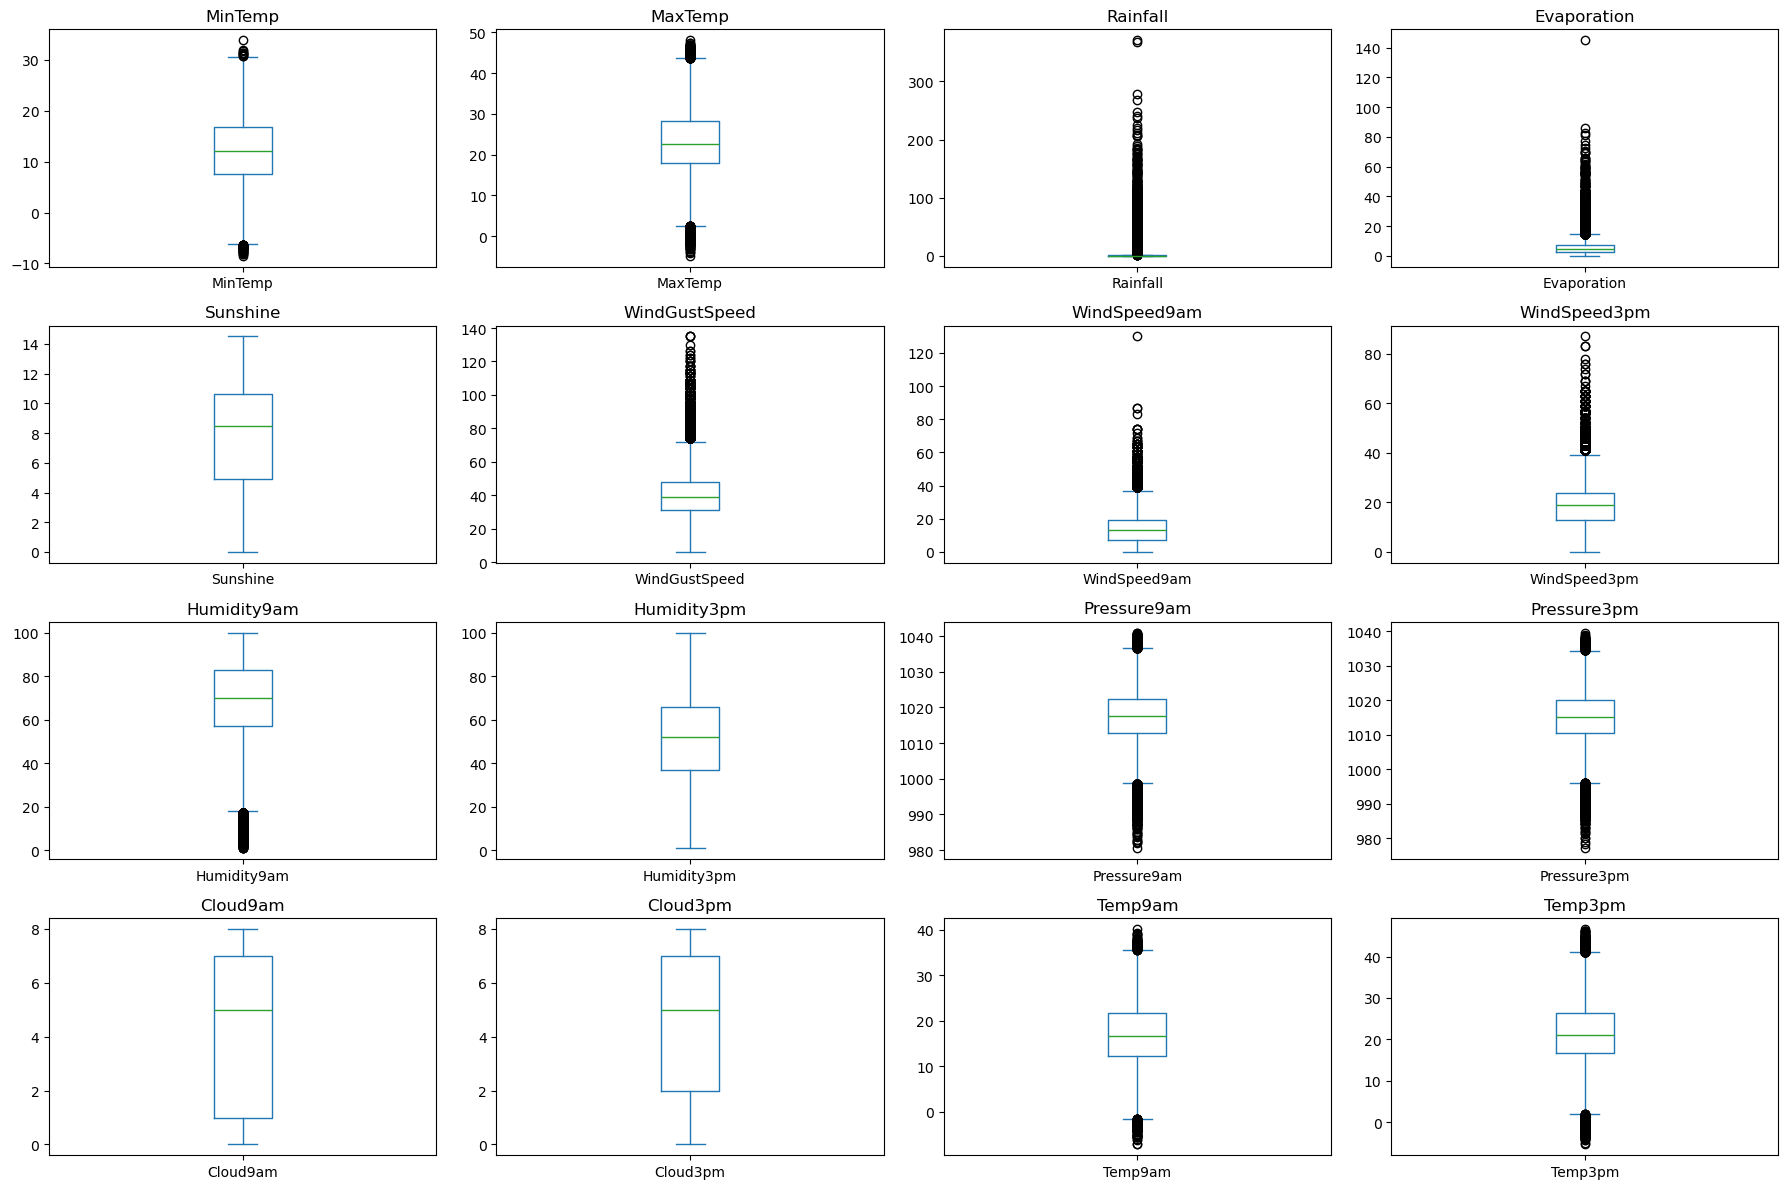

In [228]:
fig, axes = plt.subplots(4, 4, figsize=(18, 12))
for ax, col in zip(axes.flat, numerical_variables):
    df[col].plot.box(ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

2.  **Distribution of numerical variables**

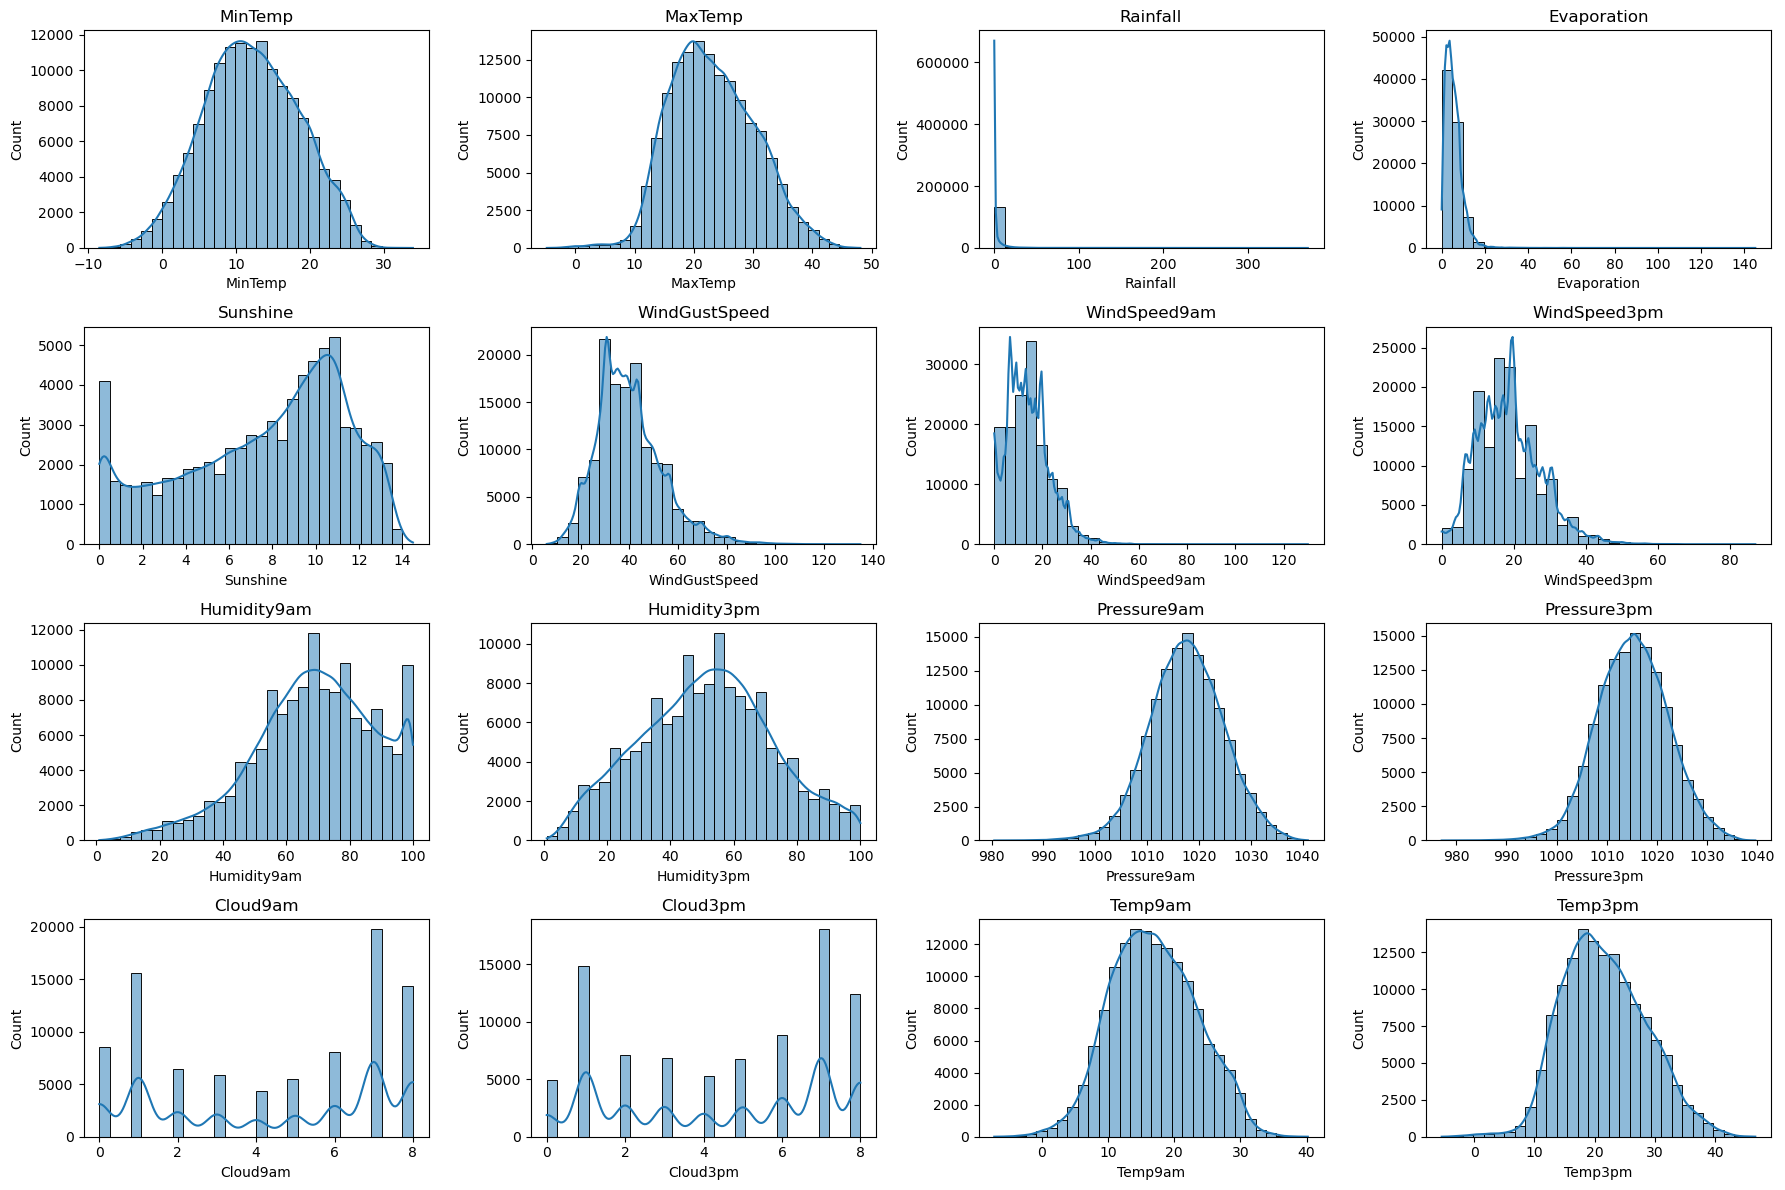

In [229]:
fig, axes = plt.subplots(4, 4, figsize=(18, 12))
for ax, col in zip(axes.flat, numerical_variables):
    #data[col].plot.hist(ax=ax, bins=30, edgecolor='black')
    sns.histplot(df[col], ax=ax, bins=30, kde=True)
    ax.set_title(col)
plt.tight_layout()
plt.show()   

3.  **Skewness Coefficient**

In [234]:
skewness = df[numerical_variables].skew()
skewness

MinTemp          0.023900
MaxTemp          0.224917
Rainfall         9.888061
Evaporation      3.746834
Sunshine        -0.502911
WindGustSpeed    0.874305
WindSpeed9am     0.775494
WindSpeed3pm     0.631433
Humidity9am     -0.482628
Humidity3pm      0.034748
Pressure9am     -0.096211
Pressure3pm     -0.046198
Cloud9am        -0.224284
Cloud3pm        -0.224097
Temp9am          0.091387
Temp3pm          0.240054
dtype: float64

4.  **Kurtosis Coefficient**

In [232]:
kurtosis = df[numerical_variables].kurtosis()
kurtosis

MinTemp           -0.487253
MaxTemp           -0.238446
Rainfall         180.002097
Evaporation       45.067784
Sunshine          -0.820364
WindGustSpeed      1.417855
WindSpeed9am       1.226555
WindSpeed3pm       0.775865
Humidity9am       -0.039881
Humidity3pm       -0.511386
Pressure9am        0.236200
Pressure3pm        0.132521
Cloud9am          -1.541201
Cloud3pm          -1.457957
Temp9am           -0.349155
Temp3pm           -0.146461
dtype: float64

**Conclusion**:

* The variables Rainfall, Evaporation are highly rigth skewed
* The variables Temp9am, Temp3pm, Pressure9am, Pressure3pm, MinTemp, MaxTemp are almost symetric (bell curve)
* The variables cloud9am, cloud3pm are discrete (ordinal) and seems to be the jointure of two or three distribution with mean (modes) 1, 7 and 8.
* The variables WindGustSpeed, WindSpeed9am, WindSpeed3pm are moderately rigth skewed.
* The variables Humidity9am, Humidity 3pm are sligthly left skewed
* The variable Sunshine seems to be sligthly left skewed with a mean equal 11 and a peak at zero 

## Visualization

1. **Target distribution ((im)balance)**

In [196]:
pd.concat([
    df['RainTomorrow'].value_counts(dropna=False),
    df['RainTomorrow'].value_counts(normalize=True, dropna=False) * 100
], axis=1, keys=['count', 'pct'])   

,count,pct
RainTomorrow,,
No,110316,77.581878
Yes,31877,22.418122


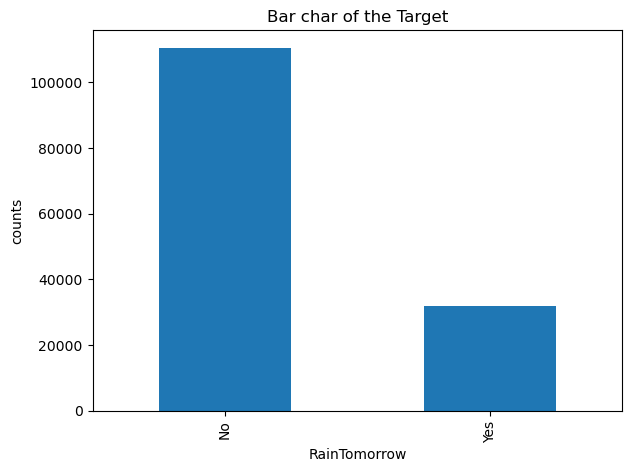

In [197]:
df['RainTomorrow'].value_counts(dropna=False).plot.bar()
plt.ylabel('counts')
# plt.xticks(rotation = 90)
plt.title('Bar char of the Target')
plt.tight_layout(pad = 1.0, w_pad = 1.0, h_pad = 1.0)
plt.show()

2. **RainToday vs RainTomorrow crosstab**

In [199]:
pd.crosstab(df['RainToday'], df['RainTomorrow'], margins=True, dropna=False)

RainTomorrow,No,Yes,All
RainToday,,,
No,92728,16604,109332.0
Yes,16858,14597,31455.0
NaN,730,676,NaN
All,110316,31877,142193.0


3.  **feature distributions by target**

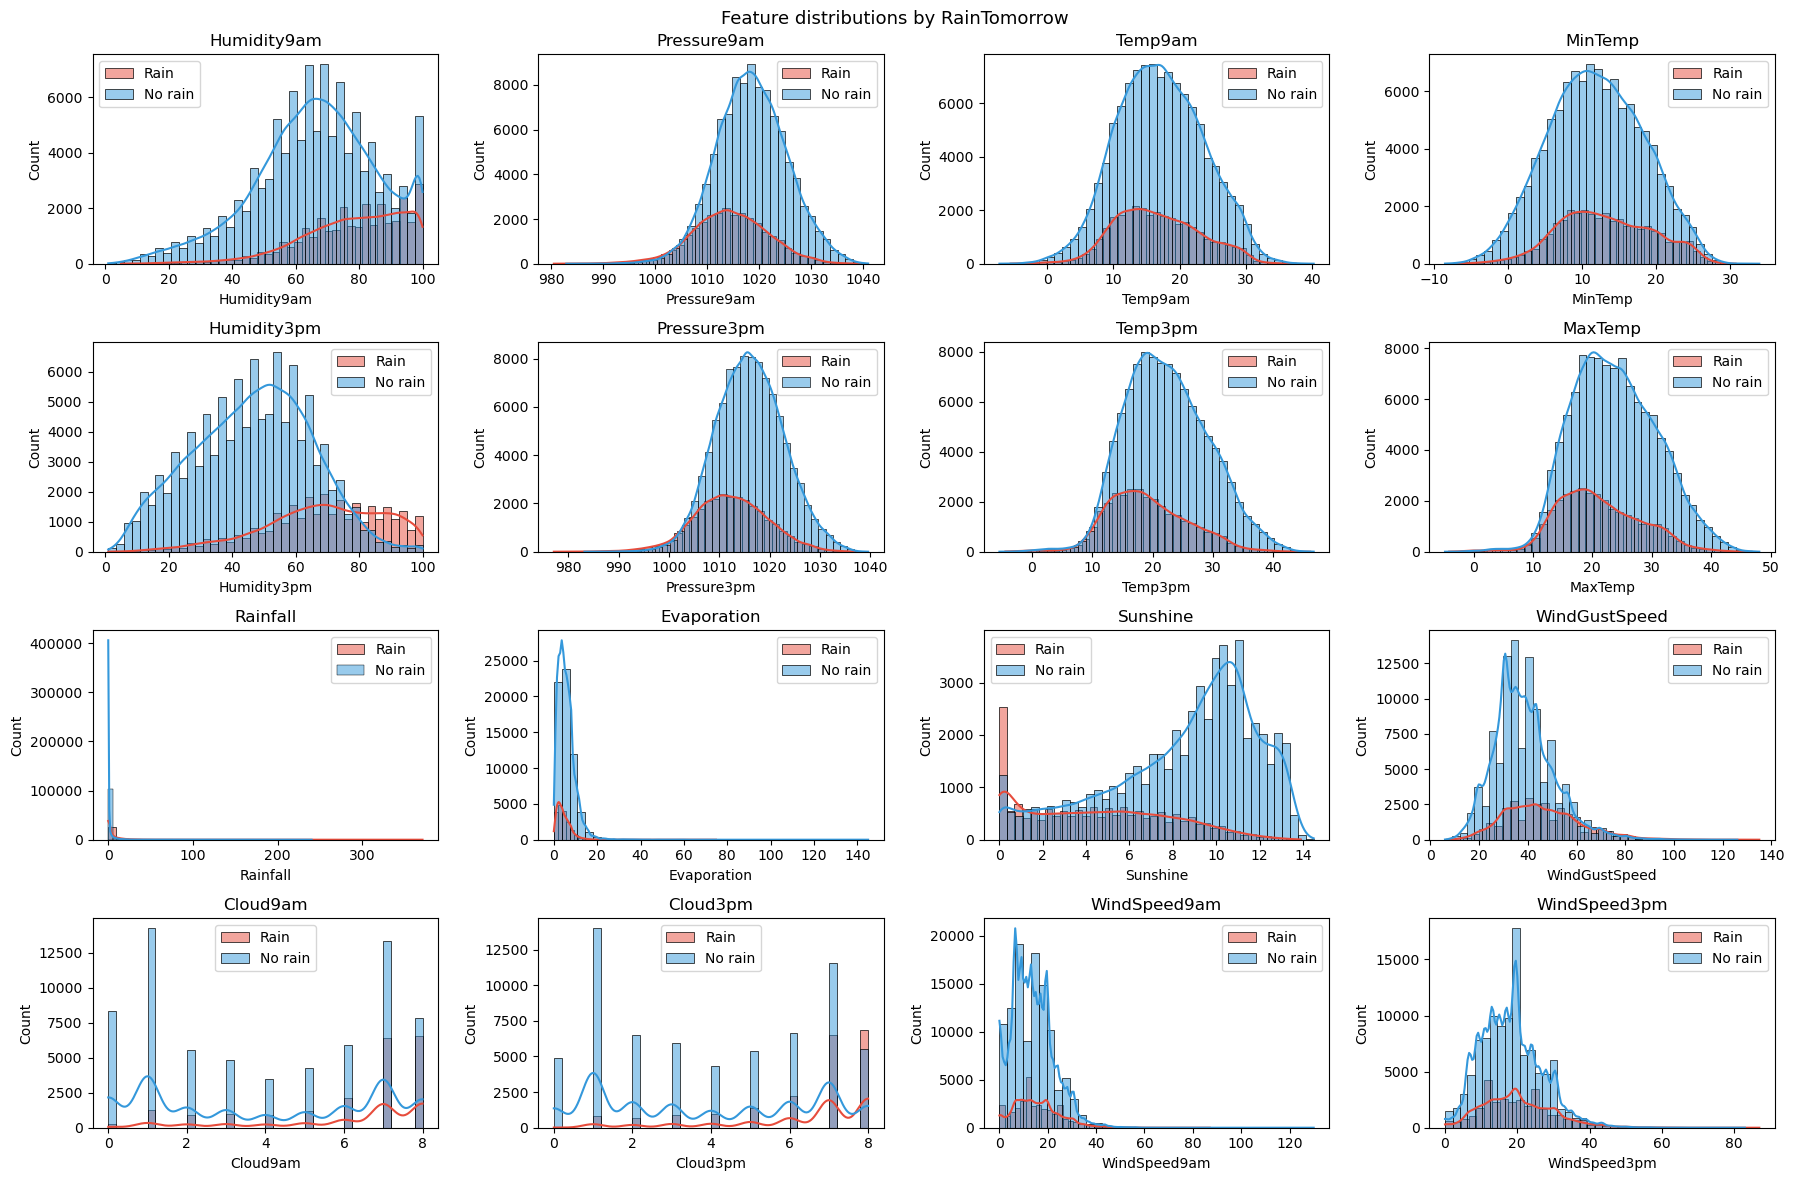

In [213]:
# Pick the most physically interpretable features
key_features = ['Humidity9am', 'Pressure9am', 'Temp9am', 'MinTemp',
                'Humidity3pm', 'Pressure3pm', 'Temp3pm', 'MaxTemp',
                'Rainfall', 'Evaporation', 'Sunshine','WindGustSpeed', 
                'Cloud9am', 'Cloud3pm', 'WindSpeed9am', 'WindSpeed3pm']

fig, axes = plt.subplots(4, 4, figsize=(18, 12))
for ax, col in zip(axes.flat, key_features):
    for target, label, color in [('Yes', 'Rain', '#e74c3c'), ('No', 'No rain', '#3498db')]:
        subset = df.loc[(df['RainTomorrow'] == target) & df[col].notna(), col]
        sns.histplot(subset, kde=True, ax=ax, label=label, color=color, alpha=0.5, bins=40)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.legend()

plt.suptitle('Feature distributions by RainTomorrow', fontsize=13)
plt.tight_layout()
plt.show()

The is clearly a link between the target and the all remaining numerical variables

4. **time-series of Rainfall**

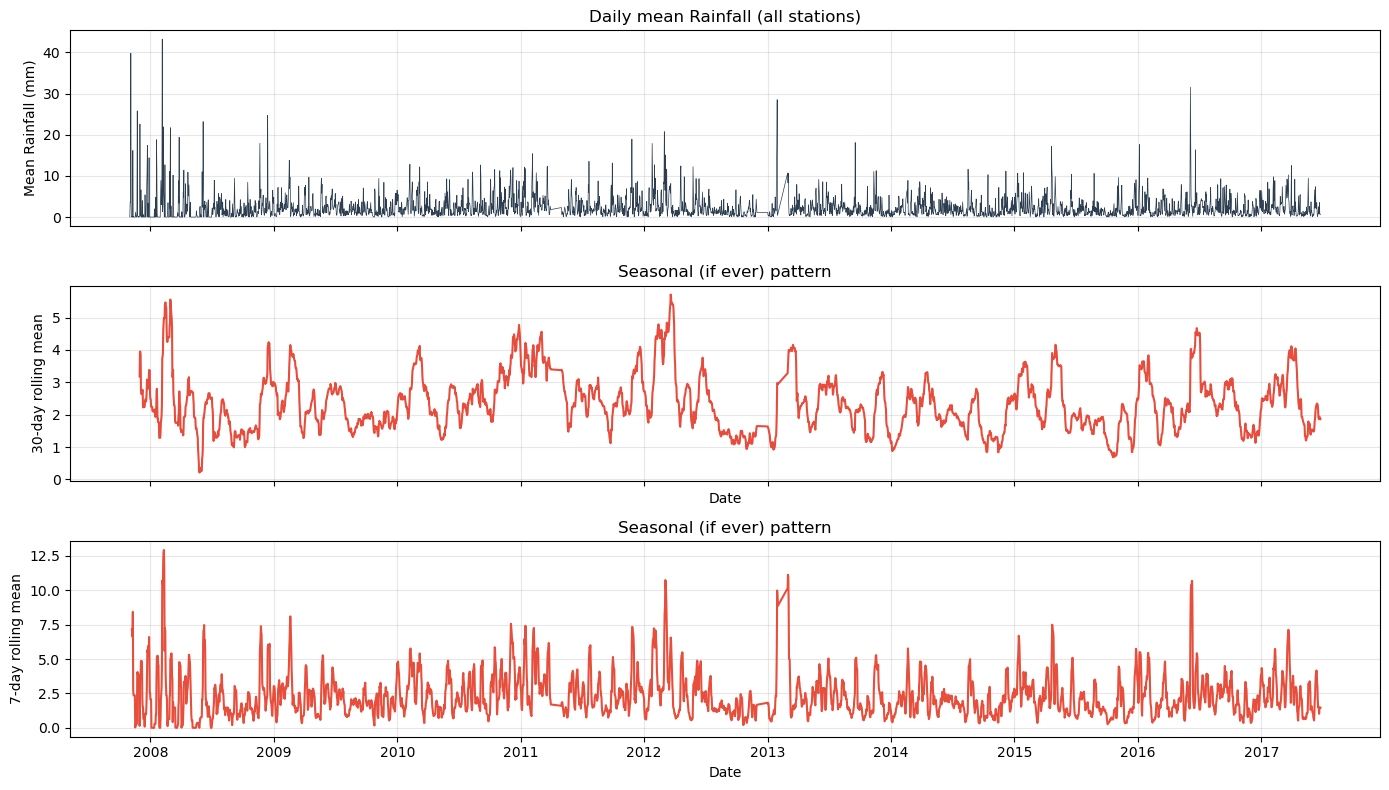

In [225]:
daily_rain = df.groupby('Date')['Rainfall'].mean().sort_index()

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

# Top: raw daily mean
axes[0].plot(daily_rain.index, daily_rain.values, color='#2c3e50', linewidth=0.5)
axes[0].set_ylabel('Mean Rainfall (mm)')
axes[0].set_title('Daily mean Rainfall (all stations)')
axes[0].grid(alpha=0.3)

# Bottom: 30-day rolling mean to show seasonality
rolling = daily_rain.rolling(30).mean()
axes[1].plot(rolling.index, rolling.values, color='#e74c3c', linewidth=1.5)
axes[1].set_ylabel('30-day rolling mean')
axes[1].set_xlabel('Date')
axes[1].set_title('Seasonal (if ever) pattern')
axes[1].grid(alpha=0.3)

# Bottom: 7-day rolling mean to show seasonality
rolling_7 = daily_rain.rolling(7).mean()
axes[2].plot(rolling_7.index, rolling_7.values, color='#e74e3c', linewidth=1.5)
axes[2].set_ylabel('7-day rolling mean')
axes[2].set_xlabel('Date')
axes[2].set_title('Seasonal (if ever) pattern')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

5. **correlation heatmap**

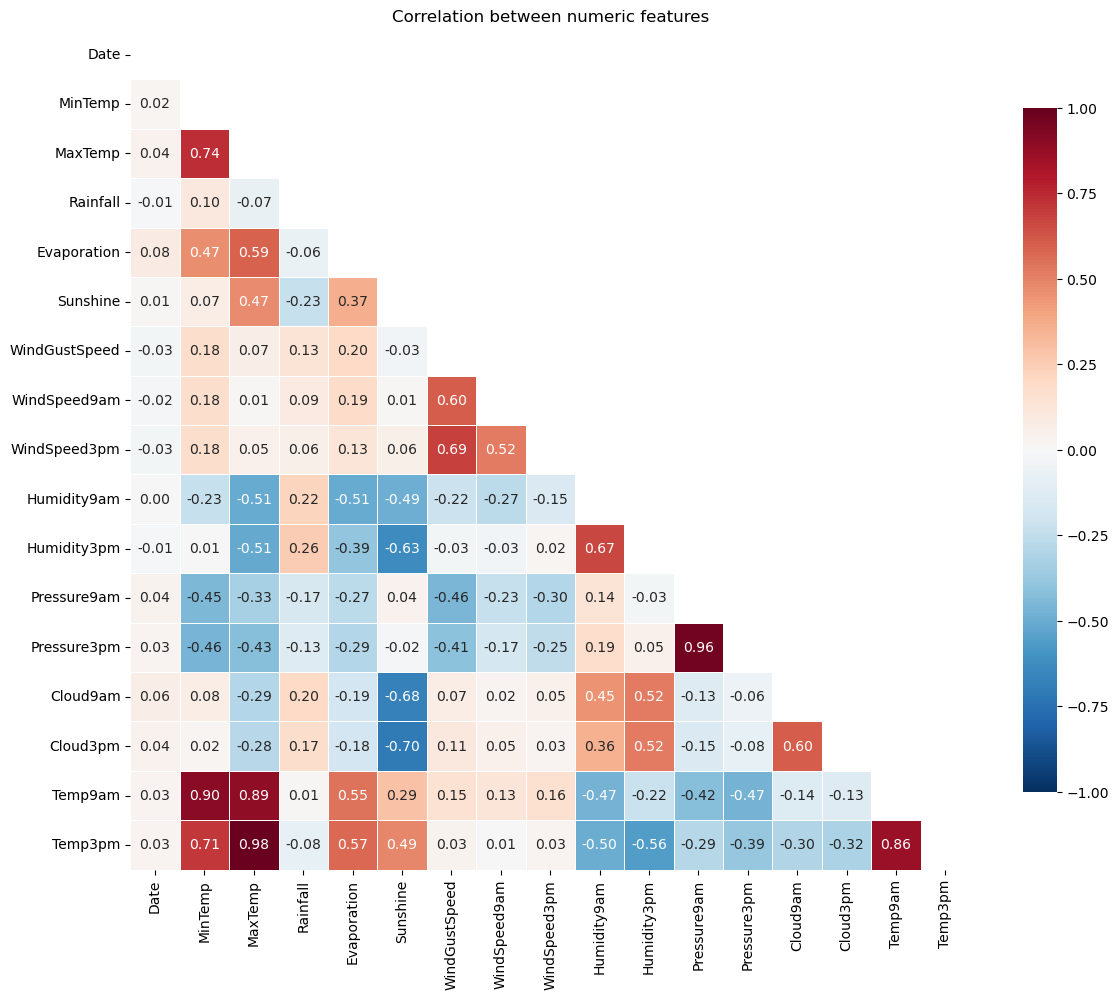

In [254]:
corr = df[numerical_variables].corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))  # hide upper triangle for readability
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8})
plt.title('Correlation between numeric features')
plt.tight_layout()
plt.show()   

6. **Correlation heatmap of categorical variable (V de Crmer)**

In [256]:
from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(x, y):
    """Cramér's V with bias correction (Bergsma & Wicher, 2013)."""
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    r, k = ct.shape
    phi2 = chi2 / n
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1)**2) / (n - 1)
    kcorr = k - ((k - 1)**2) / (n - 1)
    return np.sqrt(phi2corr / min((kcorr - 1), (rcorr - 1)))

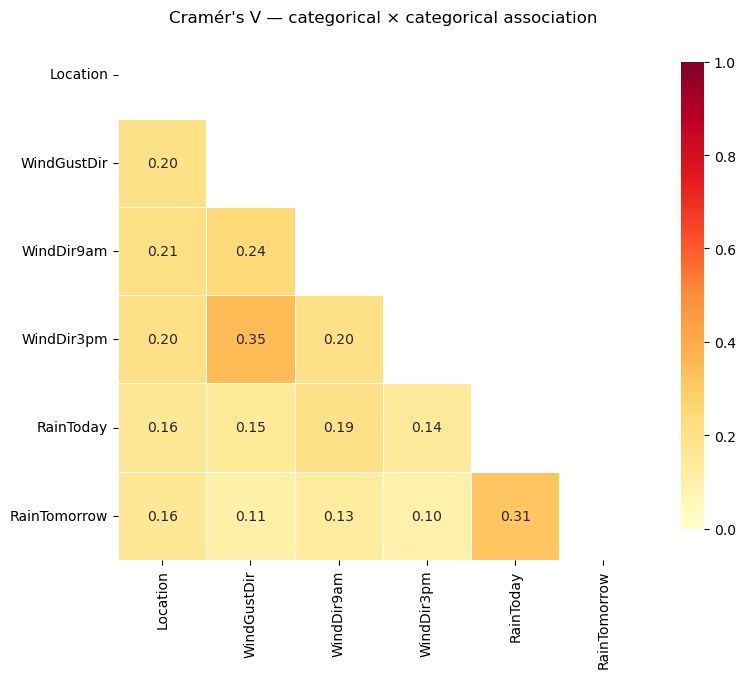

In [258]:
cat_cols = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']

# Build the matrix
n = len(cat_cols)
V = np.eye(n)
for i in range(n):
    for j in range(i + 1, n):
        v = cramers_v(df[cat_cols[i]].dropna(), df[cat_cols[j]].dropna())
        V[i, j] = V[j, i] = v

V_df = pd.DataFrame(V, index=cat_cols, columns=cat_cols)

plt.figure(figsize=(8, 7))
mask = np.triu(np.ones_like(V_df, dtype=bool)) 
sns.heatmap(V_df, mask=mask, annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Cramér's V — categorical × categorical association")
plt.tight_layout()
plt.show()   

Conclusion:

*  The target variable is imbalanced
*  There are still some missing point in RainToday (1406)
*  There obviously appear a difference among numerical variable  depending on target variable, this suggest an relationship with target variable
*   There is strong correlation between \**Temp*\* variables, \**Wind*\* variables, \**Humidity*\* with \**Cloud*\*, *Sunshine*, and *Evaporation*, and between \**Temp*\*, *Sunshine*, and *Evaporation*.
*   There is a moderate relationship between RainTomorrow and RainToday, and between WindDir3pm and WindGustDir.

## Split DATA into train, validation, test.

As we have chronological data, we have to split the data while considering the 'date' such that validation appear after train dates and test after validation dates.

In [273]:
# let's look at date range
df['Date'].describe()

count                           142193
mean     2013-04-01 00:28:51.730816512
min                2007-11-01 00:00:00
25%                2011-01-06 00:00:00
50%                2013-05-27 00:00:00
75%                2015-06-12 00:00:00
max                2017-06-25 00:00:00
Name: Date, dtype: object

In [274]:
df = df.sort_values('Date').reset_index(drop=True)

In [275]:
df['Date'].min() + pd.Timedelta(days=int(0.70*3524))

Timestamp('2014-08-02 00:00:00')

In [276]:
df['Date'].min() + pd.Timedelta(days=int(0.85*3524))

Timestamp('2016-01-13 00:00:00')

In [277]:
# Boundaries (≈ 70 / 15 / 15)
# despite the 70th date being the 02 August 2014, we decided to fix it at '2014-06-30' to facilitate the interpretability
# this choice impacted the date for the val end
train_end = pd.Timestamp('2014-06-30')
val_end   = pd.Timestamp('2015-12-31')

In [280]:
train = df[df['Date'] <= train_end].copy()
val   = df[(df['Date'] > train_end) & (df['Date'] <= val_end)].copy()
test  = df[df['Date'] > val_end].copy()

# Verify
print(f"Train : {len(train):>6}  |  {train['Date'].min().date()} → {train['Date'].max().date()}")
print(f"Val   : {len(val):>6}  |  {val['Date'].min().date()} → {val['Date'].max().date()}")
print(f"Test  : {len(test):>6}  |  {test['Date'].min().date()} → {test['Date'].max().date()}")

Train :  90210  |  2007-11-01 → 2014-06-30
Val   :  26009  |  2014-07-01 → 2015-12-31
Test  :  25974  |  2016-01-01 → 2017-06-25


In [281]:
# Sanity: no overlap
assert train['Date'].max() < val['Date'].min()
assert val['Date'].max() < test['Date'].min()

# Class balance per split (expect slight drift — that's fine, it's realistic)
for name, d in [('train', train), ('val', val), ('test', test)]:
    pct = (d['RainTomorrow'] == 'Yes').mean() * 100
    print(f"{name:>5}: {pct:.1f}% Yes")

train: 22.8% Yes
  val: 20.6% Yes
 test: 22.9% Yes


In [282]:
# Save data
train.to_csv('../data/interim/train.csv', index=False)
val.to_csv('../data/interim/val.csv', index=False)
test.to_csv('../data/interim/test.csv', index=False)   

**Conclusion**:

*  The training set covers Nov 2007 \- Jun 2014 (~ 6.7 years), validation Jul 2014 \- Dec 2015 (~ 1.5 years), 
and test Jan 2016 \- Jun 2017 (~ 1.5 years).
*  Boundaries were chosen at calendar half-year marks for interpretability."